# Escalado al dataset completo: EEGNet-style (2 canales, V2)

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve,
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

TFM_DIR = os.path.expanduser("~/Desktop/TFM")
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

NPZ_PATH = os.path.join(TFM_DIR, "datos_procesados_completo_2canales.npz")
print("Cargando datos ya procesados desde:", NPZ_PATH)

Cargando datos ya procesados desde: C:\Users\alber/Desktop/TFM\datos_procesados_completo_2canales.npz


## 1. Cargar los datos ya procesados

In [2]:
data = np.load(NPZ_PATH)

X_train_norm = data["X_train_norm"]
y_train = data["y_train"]
X_val_norm = data["X_val_norm"]
y_val = data["y_val"]
X_test_norm = data["X_test_norm"]
y_test = data["y_test"]

n_samples = X_train_norm.shape[1]
n_channels = X_train_norm.shape[2]

print("Train:", X_train_norm.shape, "| Val:", X_val_norm.shape, "| Test:", X_test_norm.shape)

Train: (205045, 3000, 2) | Val: (46265, 3000, 2) | Test: (44733, 3000, 2)


## 2. Modelo: EEGNet-style 

In [3]:
def build_eegnet_style(n_samples, n_channels, F1=16, D=2, F2=32,
                        kernel_temporal=50, kernel_separable=16, dropout_rate=0.3):
    inputs = layers.Input(shape=(n_samples, n_channels))

    x = layers.Permute((2, 1))(inputs)
    x = layers.Reshape((n_channels, n_samples, 1))(x)

    x = layers.Conv2D(F1, kernel_size=(1, kernel_temporal),
                       padding="same", use_bias=False)(x)

    x = layers.DepthwiseConv2D(kernel_size=(n_channels, 1), depth_multiplier=D,
                                use_bias=False,
                                depthwise_constraint=tf.keras.constraints.max_norm(1.))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.AveragePooling2D((1, 4))(x)
    x = layers.Dropout(dropout_rate)(x)

    new_len = x.shape[2]
    x = layers.Reshape((new_len, F1 * D))(x)

    x = layers.SeparableConv1D(F2, kernel_size=kernel_separable,
                                padding="same", use_bias=False)(x)
    x = layers.Activation("relu")(x)
    x = layers.AveragePooling1D(4)(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.GlobalAveragePooling1D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs, name="EEGNet_style")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_eegnet_style(n_samples, n_channels)
model.summary()

Model: "EEGNet_style"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3000, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 2, 3000)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 2, 3000, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 2, 3000, 16)    │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 1, 3000, 32)    │            64 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1, 3000, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 3000, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 750, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 750, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv1d                │ (None, 750, 32)        │         1,536 │
│ (SeparableConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d               │ (None, 187, 32)        │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 187, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 64 (256.00 B)

## 3. Entrenamiento — Configuración V2 

In [4]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    os.path.join(TFM_DIR, "modelo_final_eegnet_completo_v2.keras"),
    monitor="val_loss",
    save_best_only=True,
)

history = model.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    class_weight={0: 1.0, 1: (y_train == 0).sum() / max((y_train == 1).sum(), 1)},
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 281s 86ms/step - accuracy: 0.9256 - loss: 0.1928 - val_accuracy: 0.9457 - val_loss: 0.1296
Epoch 2/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 268s 84ms/step - accuracy: 0.9483 - loss: 0.1435 - val_accuracy: 0.9602 - val_loss: 0.1056
Epoch 3/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 273s 85ms/step - accuracy: 0.9587 - loss: 0.1211 - val_accuracy: 0.9669 - val_loss: 0.0918
Epoch 4/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 269s 84ms/step - accuracy: 0.9619 - loss: 0.1127 - val_accuracy: 0.9660 - val_loss: 0.0901
Epoch 5/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 275s 86ms/step - accuracy: 0.9637 - loss: 0.1069 - val_accuracy: 0.9651 - val_loss: 0.0919
Epoch 6/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 278s 87ms/step - accuracy: 0.9648 - loss: 0.1032 - val_accuracy: 0.9670 - val_loss: 0.0870
Epoch 7/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 277s 86ms/step - accuracy: 0.9655 - loss: 0.0997 - val_accuracy: 0.9665 - val_loss: 0.0892
Epoch 8/100
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 271s 85ms/step - ac

In [5]:
model.save(os.path.join(TFM_DIR, "modelo_final_eegnet_completo_v2_final.keras"))

with open(os.path.join(TFM_DIR, "historial_eegnet_completo_v2.json"), "w") as f:
    json.dump(history.history, f)

n_epochs_trained = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_loss = min(history.history["val_loss"])

print(f"Modelo e historial guardados. Épocas entrenadas: {n_epochs_trained}")
print(f"Mejor época: {best_epoch} (val_loss = {best_val_loss:.4f})")

Modelo e historial guardados. Épocas entrenadas: 42
Mejor época: 22 (val_loss = 0.0823)


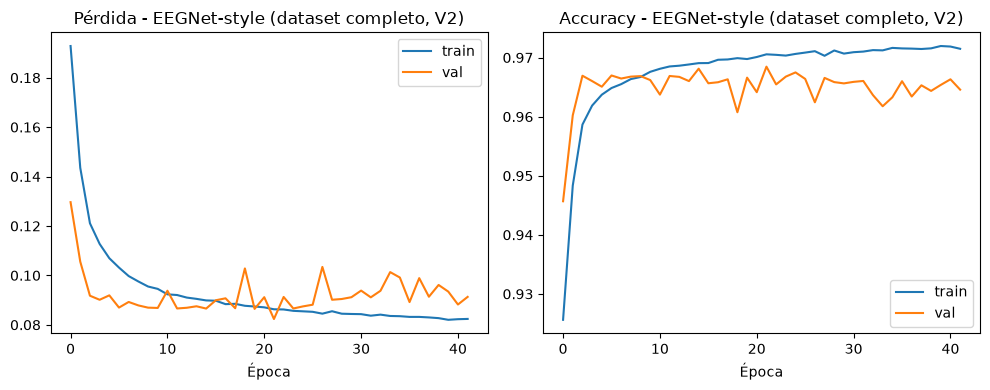

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Pérdida - EEGNet-style (dataset completo, V2)")
plt.xlabel("Época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy - EEGNet-style (dataset completo, V2)")
plt.xlabel("Época")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "curvas_entrenamiento_completo_eegnet.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## 4. Evaluación en el conjunto de test

1398/1398 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step
              precision    recall  f1-score   support

     Vigilia      0.988     0.932     0.959     25152
       Sueño      0.918     0.985     0.951     19581

    accuracy                          0.955     44733
   macro avg      0.953     0.959     0.955     44733
weighted avg      0.957     0.955     0.955     44733

ROC-AUC: 0.995


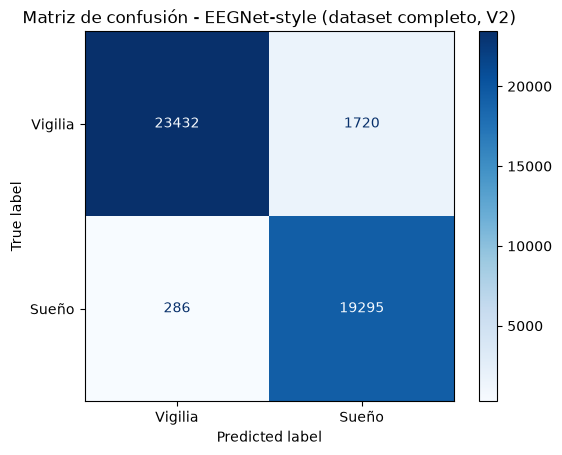

In [7]:
y_pred_prob = model.predict(X_test_norm).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["Vigilia", "Sueño"], digits=3))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"ROC-AUC: {roc_auc:.3f}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - EEGNet-style (dataset completo, V2)")
plt.savefig(os.path.join(IMAGES_DIR, "matriz_confusion_completo_eegnet.png"),
            dpi=150, bbox_inches="tight")
plt.show()

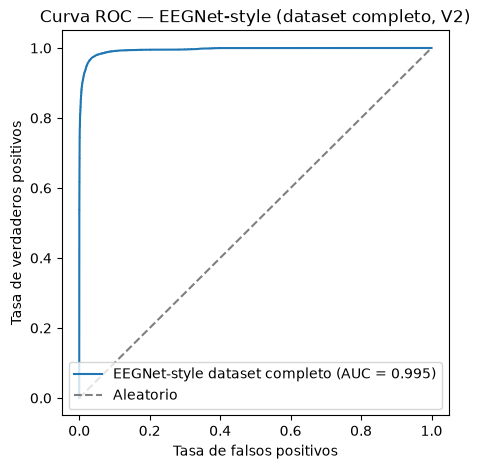

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"EEGNet-style dataset completo (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — EEGNet-style (dataset completo, V2)")
plt.legend()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curve_completo_eegnet.png"),
            dpi=150, bbox_inches="tight")
plt.show()